# Double Pendulum Simulator — Robots as Dynamical Systems

A from-scratch simulator for a planar double pendulum (the classic acrobot / pendubot model behind gymnast-style swing-up):

1. Derive the equations of motion symbolically with the **Euler–Lagrange** equation (SymPy).
2. Extract the mass-inertia matrix $\mathbf M(\mathbf q)$, the Coriolis–centrifugal vector $\mathbf C(\mathbf q,\dot{\mathbf q})$ and the gravity vector $\mathbf G(\mathbf q)$.
3. Implement the **forward dynamics** $\ddot{\mathbf q} = \mathbf f(\mathbf q,\dot{\mathbf q},\boldsymbol\tau)$.
4. Integrate with **RK4** (and explicit Euler for comparison).
5. Simulate, plot, animate, and **validate** (equation residual, energy conservation, reference solver, chaos).

## 1. Model and conventions

| Symbol | Meaning | Value |
|---|---|---|
| $m_1, m_2$ | point masses at the end of each link | 1.0 kg |
| $l_1, l_2$ | link lengths | 1.0 m |
| $g$ | gravitational acceleration | 9.81 m/s² |
| $q_1, q_2$ | **absolute** link angles, measured from the downward vertical, counter-clockwise positive | rad |
| $\tau_1, \tau_2$ | joint torques | N·m |

The links are massless rods with point masses at their ends, there is no friction, and the pivot is fixed at the origin.

Positions of the two masses:

$$
\mathbf p_1 = \begin{bmatrix} l_1\sin q_1 \\ -l_1\cos q_1 \end{bmatrix},\qquad
\mathbf p_2 = \mathbf p_1 + \begin{bmatrix} l_2\sin q_2 \\ -l_2\cos q_2 \end{bmatrix}
$$

> **Note on the angle convention.** Because $q_2$ is absolute (not relative to link 1), the torque $\tau_2$ conjugate to $q_2$ is the generalized force for that coordinate. For a relative-angle model (common for acrobots) the matrices change, but the method is identical.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.integrate import solve_ivp
from IPython.display import Image

## 2. Euler–Lagrange derivation (SymPy)

Lagrangian $L = K - V$ with

$$
K = \tfrac12 m_1 \|\dot{\mathbf p}_1\|^2 + \tfrac12 m_2 \|\dot{\mathbf p}_2\|^2,\qquad
V = m_1 g\, y_1 + m_2 g\, y_2
$$

Euler–Lagrange equation for each generalized coordinate:

$$
\frac{d}{dt}\frac{\partial L}{\partial \dot q_i} - \frac{\partial L}{\partial q_i} = \tau_i
$$

Since $L$ has no explicit time dependence, the total time derivative is expanded with the chain rule:

$$
\frac{d}{dt}\frac{\partial L}{\partial \dot q_i}
= \sum_j \frac{\partial^2 L}{\partial \dot q_i\,\partial q_j}\dot q_j
+ \sum_j \frac{\partial^2 L}{\partial \dot q_i\,\partial \dot q_j}\ddot q_j
$$

This lets us work with plain symbols $q, \dot q, \ddot q$ instead of functions of time.

In [2]:
# Symbols: generalized coordinates, velocities, accelerations
q1, q2 = sp.symbols("q1 q2")
dq1, dq2 = sp.symbols("dq1 dq2")
ddq1, ddq2 = sp.symbols("ddq1 ddq2")
tau1, tau2 = sp.symbols("tau1 tau2")

# Symbolic physical parameters (kept symbolic until lambdify)
m1_s, m2_s = sp.symbols("m1 m2", positive=True)
l1_s, l2_s = sp.symbols("l1 l2", positive=True)
g_s = sp.symbols("g", positive=True)

q = sp.Matrix([q1, q2])
dq = sp.Matrix([dq1, dq2])
ddq = sp.Matrix([ddq1, ddq2])
tau_sym = sp.Matrix([tau1, tau2])

# Forward kinematics of the two point masses
p1 = sp.Matrix([l1_s * sp.sin(q1), -l1_s * sp.cos(q1)])
p2 = p1 + sp.Matrix([l2_s * sp.sin(q2), -l2_s * sp.cos(q2)])

# Velocities via Jacobians: v = J(q) dq
v1 = p1.jacobian(q) * dq
v2 = p2.jacobian(q) * dq

# Energies and Lagrangian
K_sym = sp.simplify(sp.Rational(1, 2) * m1_s * v1.dot(v1) + sp.Rational(1, 2) * m2_s * v2.dot(v2))
V_sym = sp.simplify(m1_s * g_s * p1[1] + m2_s * g_s * p2[1])
L_sym = K_sym - V_sym

# Euler-Lagrange: d/dt(dL/ddq_i) - dL/dq_i, with the chain-rule expansion
EL = sp.Matrix([
    sum(sp.diff(L_sym, dq[i], q[j]) * dq[j] for j in range(2))
    + sum(sp.diff(L_sym, dq[i], dq[j]) * ddq[j] for j in range(2))
    - sp.diff(L_sym, q[i])
    for i in range(2)
])
EL = sp.simplify(EL)

print("Equations of motion  EL(q, dq, ddq) = tau:")
sp.pprint(sp.Eq(EL, tau_sym))

Equations of motion  EL(q, dq, ddq) = tau:
⎡   ⎛                                                 2                        ↪
⎢l₁⋅⎝ddq₁⋅l₁⋅(m₁ + m₂) + ddq₂⋅l₂⋅m₂⋅cos(q₁ - q₂) + dq₂ ⋅l₂⋅m₂⋅sin(q₁ - q₂) + g ↪
⎢                                                                              ↪
⎢                 ⎛                                    2                       ↪
⎣           l₂⋅m₂⋅⎝ddq₁⋅l₁⋅cos(q₁ - q₂) + ddq₂⋅l₂ - dq₁ ⋅l₁⋅sin(q₁ - q₂) + g⋅s ↪

↪                   ⎞⎤       
↪ ⋅(m₁ + m₂)⋅sin(q₁)⎠⎥   ⎡τ₁⎤
↪                    ⎥ = ⎢  ⎥
↪       ⎞            ⎥   ⎣τ₂⎦
↪ in(q₂)⎠            ⎦       


## 3. Extracting $\mathbf M$, $\mathbf C$ and $\mathbf G$

The equations of motion have the standard manipulator form

$$
\mathbf M(\mathbf q)\,\ddot{\mathbf q} + \mathbf C(\mathbf q,\dot{\mathbf q}) + \mathbf G(\mathbf q) = \boldsymbol\tau
$$

They are linear in $\ddot{\mathbf q}$, so:

- $\mathbf M = \partial\,\mathrm{EL} / \partial \ddot{\mathbf q}$ (Jacobian with respect to the accelerations),
- $\mathbf G = \mathrm{EL}\big|_{\ddot q = 0,\ \dot q = 0}$ (equivalently $\partial V/\partial \mathbf q$),
- $\mathbf C = \mathrm{EL}\big|_{\ddot q = 0} - \mathbf G$.

In [3]:
M_sym = sp.simplify(EL.jacobian(ddq))
bias_sym = EL.subs({ddq1: 0, ddq2: 0})
G_sym = sp.simplify(bias_sym.subs({dq1: 0, dq2: 0}))
C_sym = sp.simplify(bias_sym - G_sym)

# Sanity checks: the decomposition reproduces EL exactly, and G = dV/dq
assert sp.simplify(M_sym * ddq + C_sym + G_sym - EL) == sp.zeros(2, 1)
assert sp.simplify(G_sym - sp.Matrix([V_sym]).jacobian(q).T) == sp.zeros(2, 1)

for name, expr in [("M(q)", M_sym), ("C(q, dq)", C_sym), ("G(q)", G_sym)]:
    print(f"\n{name} =")
    sp.pprint(expr)


M(q) =
⎡      2                                     ⎤
⎢    l₁ ⋅(m₁ + m₂)      l₁⋅l₂⋅m₂⋅cos(q₁ - q₂)⎥
⎢                                            ⎥
⎢                                2           ⎥
⎣l₁⋅l₂⋅m₂⋅cos(q₁ - q₂)         l₂ ⋅m₂        ⎦

C(q, dq) =
⎡   2                       ⎤
⎢dq₂ ⋅l₁⋅l₂⋅m₂⋅sin(q₁ - q₂) ⎥
⎢                           ⎥
⎢    2                      ⎥
⎣-dq₁ ⋅l₁⋅l₂⋅m₂⋅sin(q₁ - q₂)⎦

G(q) =
⎡g⋅l₁⋅(m₁ + m₂)⋅sin(q₁)⎤
⎢                      ⎥
⎣   g⋅l₂⋅m₂⋅sin(q₂)    ⎦


Result (from SymPy, not typed by hand):

$$
\mathbf M(\mathbf q) =
\begin{bmatrix}
(m_1+m_2)l_1^2 & m_2 l_1 l_2\cos(q_1-q_2)\\
m_2 l_1 l_2\cos(q_1-q_2) & m_2 l_2^2
\end{bmatrix}
$$

$$
\mathbf C(\mathbf q,\dot{\mathbf q}) =
\begin{bmatrix}
\;\;\,m_2 l_1 l_2\sin(q_1-q_2)\,\dot q_2^2\\
-m_2 l_1 l_2\sin(q_1-q_2)\,\dot q_1^2
\end{bmatrix},
\qquad
\mathbf G(\mathbf q) =
\begin{bmatrix}
(m_1+m_2)g l_1\sin q_1\\
m_2 g l_2\sin q_2
\end{bmatrix}
$$

Physical reading:

- $\mathbf M$ is symmetric and positive definite ($\det\mathbf M = m_2 l_1^2 l_2^2\,(m_1 + m_2\sin^2(q_1-q_2)) > 0$), so it can always be inverted.
- $\mathbf C$ contains only **centrifugal** terms ($\dot q_j^2$). There are no $\dot q_1\dot q_2$ terms because absolute angles are used.
- $\mathbf G$ depends only on the configuration and vanishes at the hanging equilibrium $q = 0$.

### Numerical functions

Hand-copying long symbolic expressions into NumPy is error-prone (a sign slip in $\mathbf C$ is easy to make). The numerical functions are therefore generated directly from the SymPy expressions with `lambdify`. A hand-written version is then checked against them.

In [4]:
# Numerical parameter values
PARAMS = {m1_s: 1.0, m2_s: 1.0, l1_s: 1.0, l2_s: 1.0, g_s: 9.81}
M1, M2 = PARAMS[m1_s], PARAMS[m2_s]
L1, L2 = PARAMS[l1_s], PARAMS[l2_s]
GRAV = PARAMS[g_s]

# Generated from the symbolic expressions (single source of truth)
_M_fn = sp.lambdify((q1, q2), M_sym.subs(PARAMS), "numpy")
_C_fn = sp.lambdify((q1, q2, dq1, dq2), C_sym.subs(PARAMS), "numpy")
_G_fn = sp.lambdify((q1, q2), G_sym.subs(PARAMS), "numpy")


def mass_matrix(q):
    # Mass-inertia matrix M(q), shape (2, 2)
    return np.array(_M_fn(*q), dtype=float)


def coriolis_vector(q, dq):
    # Coriolis-centrifugal vector C(q, dq), shape (2,)
    return np.array(_C_fn(*q, *dq), dtype=float).ravel()


def gravity_vector(q):
    # Gravity vector G(q), shape (2,)
    return np.array(_G_fn(*q), dtype=float).ravel()

In [5]:
# Independent hand-written implementation, used only as a cross-check
def mass_matrix_manual(q):
    c = np.cos(q[0] - q[1])
    return np.array([[(M1 + M2) * L1**2, M2 * L1 * L2 * c],
                     [M2 * L1 * L2 * c,  M2 * L2**2]])


def coriolis_vector_manual(q, dq):
    s = np.sin(q[0] - q[1])
    return np.array([ M2 * L1 * L2 * s * dq[1]**2,
                     -M2 * L1 * L2 * s * dq[0]**2])


def gravity_vector_manual(q):
    return np.array([(M1 + M2) * GRAV * L1 * np.sin(q[0]),
                     M2 * GRAV * L2 * np.sin(q[1])])


rng = np.random.default_rng(0)
for _ in range(100):
    q_r, dq_r = rng.uniform(-np.pi, np.pi, 2), rng.uniform(-5, 5, 2)
    assert np.allclose(mass_matrix(q_r), mass_matrix_manual(q_r))
    assert np.allclose(coriolis_vector(q_r, dq_r), coriolis_vector_manual(q_r, dq_r))
    assert np.allclose(gravity_vector(q_r), gravity_vector_manual(q_r))
print("lambdify and manual implementations agree on 100 random states.")

# Example evaluation
q_test, dq_test = np.array([0.5, 0.3]), np.array([0.2, 0.4])
print("\nM =\n", mass_matrix(q_test))
print("C =", coriolis_vector(q_test, dq_test))
print("G =", gravity_vector(q_test))

lambdify and manual implementations agree on 100 random states.

M =
 [[2.         0.98006658]
 [0.98006658 1.        ]]
C = [ 0.03178709 -0.00794677]
G = [9.40632907 2.89905323]


## 4. Forward dynamics

Solving the equations of motion for the accelerations:

$$
\ddot{\mathbf q} = \mathbf M(\mathbf q)^{-1}\big[\boldsymbol\tau - \mathbf C(\mathbf q,\dot{\mathbf q}) - \mathbf G(\mathbf q)\big]
$$

In code the linear system $\mathbf M\ddot{\mathbf q} = \mathbf b$ is solved with `np.linalg.solve` rather than by forming $\mathbf M^{-1}$ explicitly, which is cheaper and numerically more stable.

In [6]:
def forward_dynamics(q, dq, tau):
    # Joint accelerations ddq = M^-1 (tau - C - G)
    rhs = tau - coriolis_vector(q, dq) - gravity_vector(q)
    return np.linalg.solve(mass_matrix(q), rhs)


tau_zero = np.zeros(2)
ddq_test = forward_dynamics(q_test, dq_test, tau_zero)

# Residual check: plug ddq back into the equations of motion
residual = mass_matrix(q_test) @ ddq_test + coriolis_vector(q_test, dq_test) + gravity_vector(q_test) - tau_zero
print("ddq      =", ddq_test)
print("residual =", residual)
assert np.allclose(residual, 0.0)

# Static check: at the hanging equilibrium with zero torque, nothing accelerates
assert np.allclose(forward_dynamics(np.zeros(2), np.zeros(2), tau_zero), 0.0)

ddq      = [-6.35385582  3.33609528]
residual = [ 0.0000000e+00 -4.4408921e-16]


## 5. Integration

With the state $\mathbf x = [q_1, q_2, \dot q_1, \dot q_2]^T$ the second-order system becomes first order:

$$
\dot{\mathbf x} = \begin{bmatrix}\dot{\mathbf q}\\ \mathbf f(\mathbf q,\dot{\mathbf q},\boldsymbol\tau)\end{bmatrix}
$$

**Explicit Euler** (1st order): $\mathbf x_{k+1} = \mathbf x_k + \Delta t\,\dot{\mathbf x}(\mathbf x_k)$

**Runge–Kutta 4** (4th order):

$$
\begin{aligned}
k_1 &= f(t_k,\ \mathbf x_k), &
k_2 &= f(t_k+\tfrac{\Delta t}{2},\ \mathbf x_k+\tfrac{\Delta t}{2}k_1),\\
k_3 &= f(t_k+\tfrac{\Delta t}{2},\ \mathbf x_k+\tfrac{\Delta t}{2}k_2), &
k_4 &= f(t_k+\Delta t,\ \mathbf x_k+\Delta t\,k_3),
\end{aligned}
\qquad
\mathbf x_{k+1} = \mathbf x_k + \tfrac{\Delta t}{6}(k_1+2k_2+2k_3+k_4)
$$

The torque is passed as a **function** `tau(t, x)`. A constant torque, an open-loop signal or a feedback controller (for example for swing-up) can therefore all be used with the same simulator.

In [7]:
def constant_torque(value):
    # Wraps a constant torque vector as a tau(t, x) function
    value = np.asarray(value, dtype=float)
    return lambda t, x: value


def state_derivative(t, x, tau_fn):
    # dx/dt = [dq, ddq] for state x = [q1, q2, dq1, dq2]
    q, dq = x[:2], x[2:]
    return np.concatenate((dq, forward_dynamics(q, dq, tau_fn(t, x))))


def euler_step(t, x, tau_fn, dt):
    return x + dt * state_derivative(t, x, tau_fn)


def rk4_step(t, x, tau_fn, dt):
    k1 = state_derivative(t,          x,               tau_fn)
    k2 = state_derivative(t + dt / 2, x + dt / 2 * k1, tau_fn)
    k3 = state_derivative(t + dt / 2, x + dt / 2 * k2, tau_fn)
    k4 = state_derivative(t + dt,     x + dt * k3,     tau_fn)
    return x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


def simulate(x0, tau_fn, tf, dt, step=rk4_step):
    # Returns time T (N,), states X (N, 4), torques U (N, 2)
    T = np.arange(0.0, tf + dt / 2, dt)   # dt/2 guards against float round-off
    X = np.zeros((len(T), 4))
    U = np.zeros((len(T), 2))
    X[0] = x0
    for k in range(len(T) - 1):
        U[k] = tau_fn(T[k], X[k])
        X[k + 1] = step(T[k], X[k], tau_fn, dt)
    U[-1] = tau_fn(T[-1], X[-1])
    return T, X, U

In [8]:
def mechanical_energy(X):
    # Total energy E = K + V along a trajectory X (N, 4)
    q1v, q2v, dq1v, dq2v = X.T
    K = (0.5 * (M1 + M2) * L1**2 * dq1v**2
         + 0.5 * M2 * L2**2 * dq2v**2
         + M2 * L1 * L2 * np.cos(q1v - q2v) * dq1v * dq2v)
    V = -(M1 + M2) * GRAV * L1 * np.cos(q1v) - M2 * GRAV * L2 * np.cos(q2v)
    return K, V, K + V


def link_positions(X):
    # Cartesian positions of both masses for each state
    x1 = L1 * np.sin(X[:, 0]); y1 = -L1 * np.cos(X[:, 0])
    x2 = x1 + L2 * np.sin(X[:, 1]); y2 = y1 - L2 * np.cos(X[:, 1])
    return x1, y1, x2, y2


# Cross-check of the energy formula against the symbolic K and V
K_num = sp.lambdify((q1, q2, dq1, dq2), K_sym.subs(PARAMS), "numpy")
V_num = sp.lambdify((q1, q2), V_sym.subs(PARAMS), "numpy")
x_r = rng.uniform(-2, 2, (5, 4))
assert np.allclose(mechanical_energy(x_r)[2], K_num(*x_r.T) + V_num(*x_r[:, :2].T))

## 6. Simulation 1 — small oscillation

Initial state $\mathbf x_0 = [0.5,\ 0.3,\ 0.2,\ 0.4]^T$, zero torque, $t_f = 10$ s, $\Delta t = 0.005$ s.

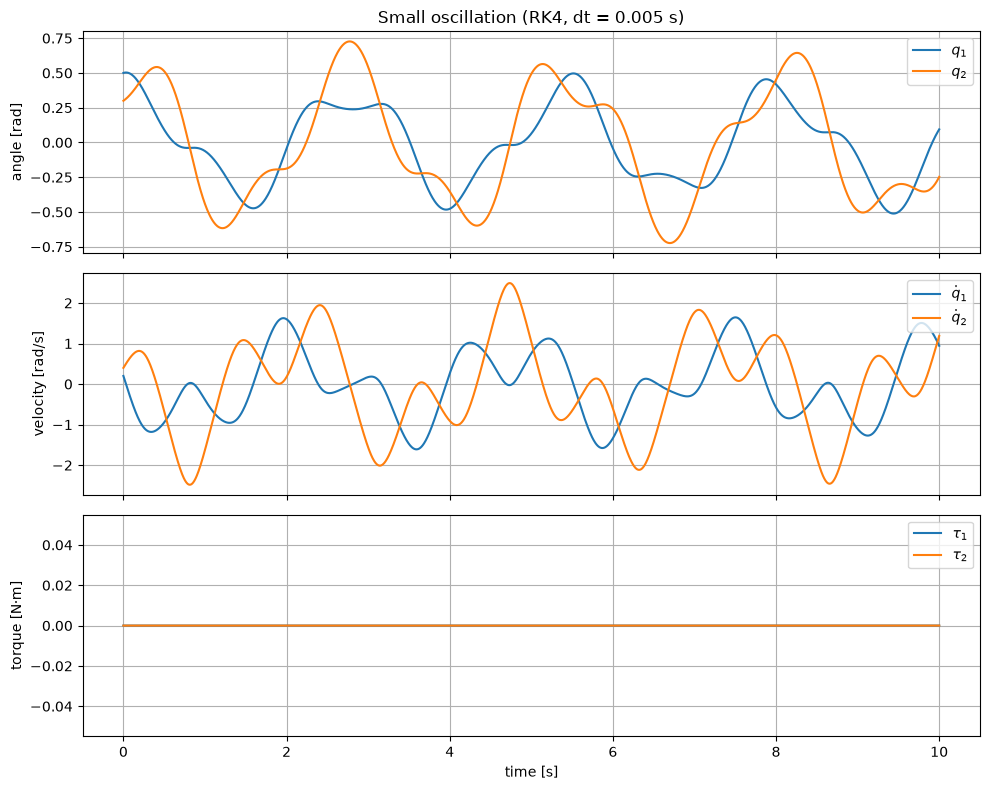

final state           : [ 0.09417 -0.24736  0.94451  1.18695]
max |E(t) - E(0)|     : 7.06e-09 J


In [9]:
def plot_timeseries(T, X, U, title):
    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(T, X[:, 0], label="$q_1$"); axes[0].plot(T, X[:, 1], label="$q_2$")
    axes[0].set_ylabel("angle [rad]")
    axes[1].plot(T, X[:, 2], label=r"$\dot q_1$"); axes[1].plot(T, X[:, 3], label=r"$\dot q_2$")
    axes[1].set_ylabel("velocity [rad/s]")
    axes[2].plot(T, U[:, 0], label=r"$\tau_1$"); axes[2].plot(T, U[:, 1], label=r"$\tau_2$")
    axes[2].set_ylabel("torque [N·m]"); axes[2].set_xlabel("time [s]")
    for ax in axes:
        ax.grid(True); ax.legend(loc="upper right")
    axes[0].set_title(title)
    fig.tight_layout()
    return fig


x0_small = np.array([0.5, 0.3, 0.2, 0.4])
T1, X1, U1 = simulate(x0_small, constant_torque([0.0, 0.0]), tf=10.0, dt=0.005)
plot_timeseries(T1, X1, U1, "Small oscillation (RK4, dt = 0.005 s)")
plt.show()

_, _, E1 = mechanical_energy(X1)
print("final state           :", X1[-1].round(5))
print(f"max |E(t) - E(0)|     : {np.max(np.abs(E1 - E1[0])):.2e} J")

## 7. Simulation 2 — large swing (chaotic regime)

Initial state $\mathbf x_0 = [2.0,\ 2.5,\ 0,\ 0]^T$, released from rest high up. This case is strongly nonlinear.

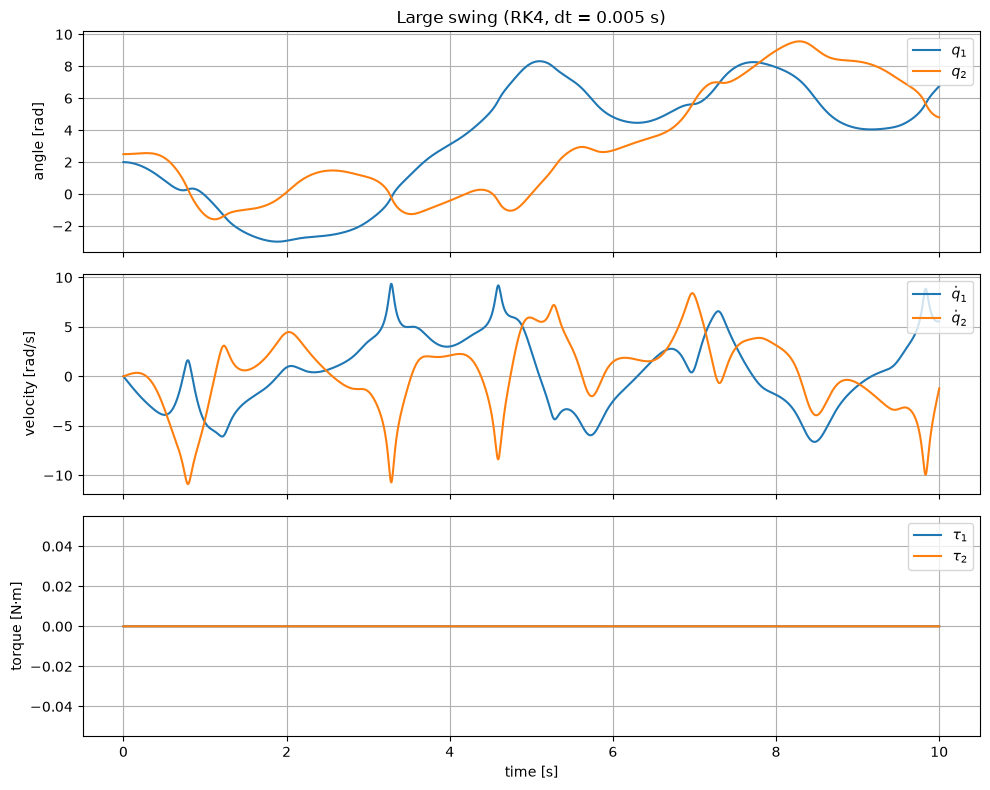

In [10]:
x0_large = np.array([2.0, 2.5, 0.0, 0.0])
T2, X2, U2 = simulate(x0_large, constant_torque([0.0, 0.0]), tf=10.0, dt=0.005)
plot_timeseries(T2, X2, U2, "Large swing (RK4, dt = 0.005 s)")
plt.show()

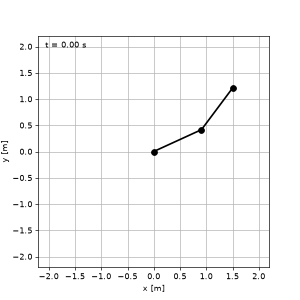

In [11]:
def animate(T, X, every=4, interval=20):
    x1, y1, x2, y2 = link_positions(X)
    R = (L1 + L2) * 1.1
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_xlim(-R, R); ax.set_ylim(-R, R); ax.set_aspect("equal"); ax.grid(True)
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    trail, = ax.plot([], [], "-", color="tab:blue", alpha=0.3, lw=1)
    rods, = ax.plot([], [], "o-", color="black", lw=2, markersize=7)
    label = ax.text(0.03, 0.95, "", transform=ax.transAxes)
    frames = np.arange(0, len(T), every)

    def update(n):
        i = frames[n]
        rods.set_data([0, x1[i], x2[i]], [0, y1[i], y2[i]])
        trail.set_data(x2[max(0, i - 300):i + 1], y2[max(0, i - 300):i + 1])
        label.set_text(f"t = {T[i]:.2f} s")
        return rods, trail, label

    anim = FuncAnimation(fig, update, frames=len(frames), interval=interval, blit=True)
    plt.close(fig)
    return anim


# Saved as a GIF so the animation also renders on GitHub (to_jshtml() would bloat the notebook)
anim = animate(T2, X2, every=8)
anim.save("../media/double_pendulum.gif", writer=PillowWriter(fps=25), dpi=60)
Image(filename="../media/double_pendulum.gif")

## 8. Validation

### 8.1 Energy conservation: RK4 vs. explicit Euler

With $\boldsymbol\tau = 0$ and no friction, the total energy $E = K + V$ must stay constant. Any drift is purely **numerical error**.

method   dt [s]   max |dE| [J]
 Euler     0.01       1.77e+01
 Euler    0.005       9.80e+00
 Euler    0.001       2.04e+00
   RK4     0.01       2.22e-03


   RK4    0.005       7.82e-05


   RK4    0.001       1.42e-07


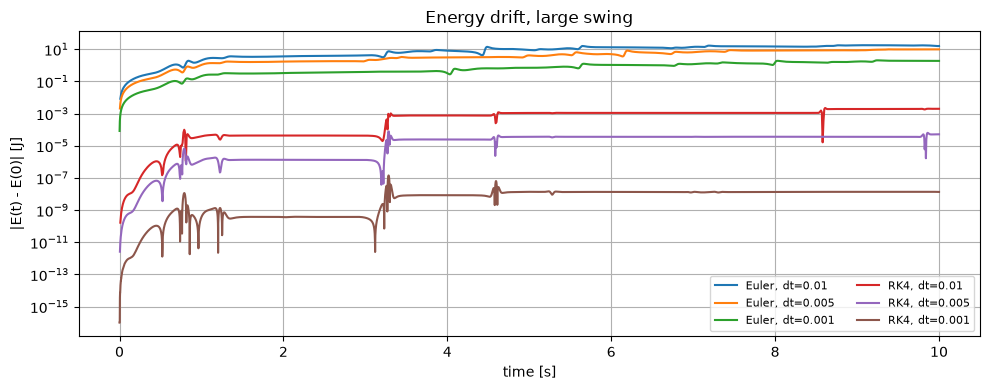

In [12]:
tau0 = constant_torque([0.0, 0.0])
fig, ax = plt.subplots(figsize=(10, 4))
print(f"{'method':>6} {'dt [s]':>8} {'max |dE| [J]':>14}")
for step, name in [(euler_step, "Euler"), (rk4_step, "RK4")]:
    for dt in (0.01, 0.005, 0.001):
        T, X, _ = simulate(x0_large, tau0, tf=10.0, dt=dt, step=step)
        _, _, E = mechanical_energy(X)
        drift = np.abs(E - E[0])
        print(f"{name:>6} {dt:>8} {drift.max():>14.2e}")
        ax.semilogy(T[1:], drift[1:] + 1e-16, label=f"{name}, dt={dt}")
ax.set_xlabel("time [s]"); ax.set_ylabel("|E(t) - E(0)| [J]")
ax.set_title("Energy drift, large swing"); ax.grid(True, which="both"); ax.legend(ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig("../media/energy_drift.png", dpi=110); plt.show()

### 8.2 Comparison against a reference solver

`scipy.integrate.solve_ivp` (adaptive DOP853, very tight tolerances) serves as a reference for the small-oscillation case.

In [13]:
ref = solve_ivp(lambda t, x: state_derivative(t, x, tau0), (0.0, 10.0), x0_small,
                method="DOP853", t_eval=T1, rtol=1e-12, atol=1e-12)
err = np.max(np.abs(ref.y.T - X1), axis=0)
print("max |x_RK4 - x_ref| per state [q1, q2, dq1, dq2]:", err)

max |x_RK4 - x_ref| per state [q1, q2, dq1, dq2]: [3.98719491e-08 5.43041304e-08 2.09820886e-07 2.95596804e-07]


### 8.3 Sensitivity to initial conditions (chaos)

Two large-swing simulations whose initial $q_1$ differs by only $10^{-9}$ rad.

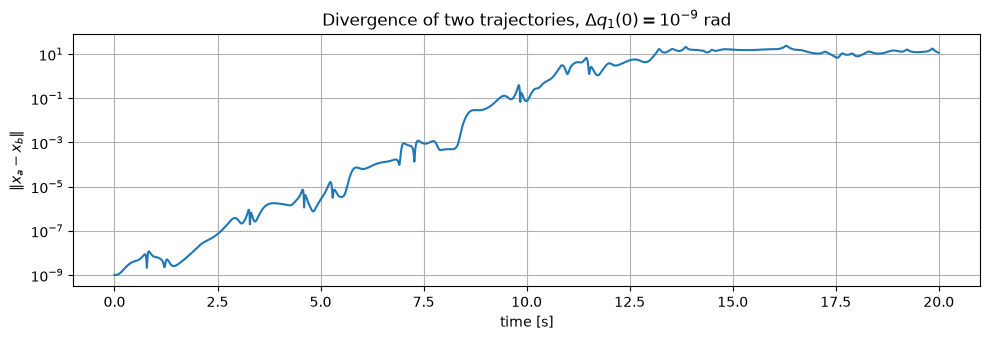

separation at t=10 s: 7.57e-02,  at t=20 s: 1.15e+01


In [14]:
_, Xa, _ = simulate(x0_large, tau0, tf=20.0, dt=0.005)
Tb, Xb, _ = simulate(x0_large + np.array([1e-9, 0, 0, 0]), tau0, tf=20.0, dt=0.005)
sep = np.linalg.norm(Xa - Xb, axis=1)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.semilogy(Tb, sep + 1e-18)
ax.set_xlabel("time [s]"); ax.set_ylabel(r"$\|x_a - x_b\|$")
ax.set_title(r"Divergence of two trajectories, $\Delta q_1(0) = 10^{-9}$ rad"); ax.grid(True, which="both")
fig.tight_layout(); plt.show()
print(f"separation at t=10 s: {sep[np.searchsorted(Tb, 10.0)]:.2e},  at t=20 s: {sep[-1]:.2e}")

## 9. Discussion

- **Correctness.** The symbolic decomposition reproduces the Euler–Lagrange equations exactly. The lambdified and hand-written $\mathbf M,\mathbf C,\mathbf G$ agree. The forward dynamics satisfies the equations of motion to machine precision, and the hanging equilibrium is a fixed point.
- **Integrator.** For a conservative system the energy drift is a direct measure of integration error. RK4 is several orders of magnitude better than explicit Euler at the same $\Delta t$, while Euler steadily *adds* energy. RK4 is still not symplectic, so over very long horizons a symplectic scheme (for example velocity Verlet) or an adaptive solver would be preferable.
- **Chaos.** In the large-swing regime, a $10^{-9}$ rad change grows exponentially until it is as large as the motion itself. Individual long-horizon trajectories are therefore not reproducible, even though invariants like energy are. Validation should rely on such invariants rather than on comparing final states.
- **Limitations.** The model uses point masses, massless rods, no friction and no joint limits, and the torque is held constant within each RK4 step. Real links have distributed inertia ($I_{cm}$ terms in $\mathbf M$) and friction.
- **Next step.** Because `simulate` accepts `tau(t, x)`, an energy-based swing-up controller acting only on $\tau_2$ (acrobot, like a gymnast's hip) can be plugged in directly.